# Pendahuluan

Sebuah sensus populasi di US dilakukan setiap 10 tahun, tabel berikut memperlihatkan jumlah populasi (dalam juta) dari tahun 1950 hingga 2000

$$
\begin{array}{c}
    \hline
    \textbf{Tahun} & \textbf{Populasi (dalam ribuan)} \\
    \hline
    1950 & 151,326 \\
    1960 & 179,323 \\
    1970 & 203,302 \\
    1980 & 226,542 \\
    1990 & 249,633 \\
    2000 & 281,422 \\
    \hline
\end{array}
$$
Ketika melihat data ini, akan timbul pertanyaan bagaimana cara melakukan estimasi terhadap populasi. Estimasi ini bisa dilakukan dengan membuat fungsi yang melewati semua titik yang cocok dengan data yang diberikan. Proses ini disebut interpolasi.

Polinom digunakan untuk memetakan sebuah kumpulan angka hingga membentuk persamaan polinom. Persamaan polinom sebagai berikut.
$$
P_n(x) = a_nx^n + a_{n-1}x^{n-1} + \dots + a_1x + a_0
$$

Di mana n adalah bilangan bulat non negatif dan $a_0, \dots, a_n$ adalah konstan ril. Artinya, ketika diberikan suatu fungsi, yang didefinisikan dan kontinu pada suatu interval tertutup dan terbatas, terdapat suatu polinomial yang sedekat mungkin dengan fungsi yang diberikan sebagaimana yang diinginkan.

Hasil estimasi ini digambarkan secara akurat dalam Teorema Aproksimasi Weierstrass. Misalnya fungsi $f$ terdefinisi dan kontinyu pada interval $[a,b]$. Untuk setiap $ϵ > 0$, ada polinom $P(x)$ dengan sifat bahwa
$$
\quad |f(x) - P(x)| < \epsilon, \quad \forall x \in [a,b] \quad
$$

Salah satu alasan penggunaan polinom untuk aproksimasi fungsi adalah turunan dan integral tak-tentu nya mudah untuk dihitung.

Dalam tugas ini akan dilakukan estimasi populasi pada tahun 1975 dengan data populasi menggunakan 3 metode sebagai berikut.
1. Metode newton (mundur/backward, sentral/central, dan maju/forward)
2. Metode Lagrange
3. Metode Neville

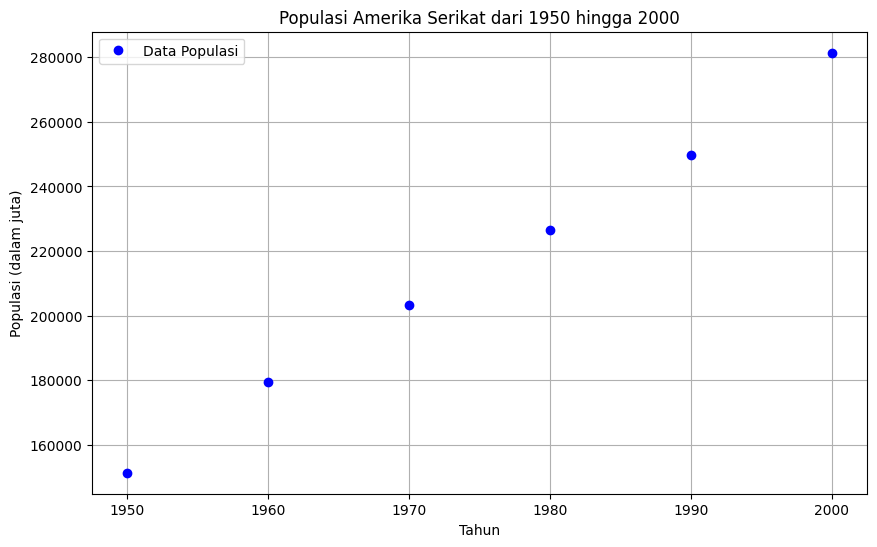

In [1]:
# Import library
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

# Definisikan data
tahun = np.array([1950, 1960, 1970, 1980, 1990, 2000])
populasi = np.array([151326, 179323, 203302, 226542, 249633, 281422])

# Plotting awal
plt.figure(figsize=(10, 6))
plt.plot(tahun, populasi, marker='o', linestyle='', color='b', label='Data Populasi')
plt.title('Populasi Amerika Serikat dari 1950 hingga 2000')
plt.xlabel('Tahun')
plt.ylabel('Populasi (dalam juta)')
plt.legend()
plt.grid(True)
plt.show()

# Polinom Lagrange

## Pendahuluan
Masalah menentukan polinomial derajat satu yang melalui titik-titik berbeda $(x_0, y_0)$ dan $(x_1, y_1)$ adalah sama dengan memperkirakan fungsi $f$ yang memenuhi $f(x_0) = y_0$ dan $f(x_1) = y_1$ dengan menggunakan polinomial interpolasi derajat satu, yang sejalan dengan nilai-nilai $f$ pada titik-titik yang diberikan. Menggunakan polinomial ini untuk aproksimasi dalam interval yang diberikan oleh titik akhir disebut interpolasi polinomial.

Definisikan fungsi-fungsi
$$
L_0(x) = \frac{x - x_1}{x_0 - x_1} \quad \text{dan} \quad L_1(x) = \frac{x - x_0}{x_1 - x_0}
$$

Polinomial interpolasi Lagrange linear melalui $(x_0, y_0)$ dan $(x_1, y_1)$ adalah
$$
P(x) = L_0(x)f(x_0) + L_1(x)f(x_1) = \frac{x - x_1}{x_0 - x_1}f(x_0) + \frac{x - x_0}{x_1 - x_0}f(x_1).
$$

Perhatikan bahwa
$$
L_0(x_0) = 1, \quad L_0(x_1) = 0, \quad L_1(x_0) = 0, \quad \text{dan} \quad L_1(x_1) = 1,
$$
yang mengimplikasikan bahwa
$$
P(x_0) = 1 \cdot f(x_0) + 0 \cdot f(x_1) = f(x_0) = y_0
$$
dan
$$
P(x_1) = 0 \cdot f(x_0) + 1 \cdot f(x_1) = f(x_1) = y_1.
$$
Jadi, $P$ adalah polinomial unik dengan derajat paling tinggi satu yang melalui $(x_0, y_0)$ dan $(x_1, y_1)$. Untuk menggeneralisasi konsep interpolasi linier, pertimbangkan konstruksi polinomial dengan derajat paling tinggi n yang melalui n + 1 titik
$(x_0, f(x_0)), (x_1, f(x_1)), \ldots, (x_n, f(x_n))$.

Dalam hal ini, pertama-tama akan dibangun untuk setiap $k = 0, 1, \ldots, n$, sebuah fungsi $L_{n,k}(x)$ dengan sifat bahwa $L_{n,k}(x_i) = 0$ ketika $i = k$ dan $L_{n,k}(x_k) = 1$. Untuk memenuhi $L_{n,k}(x_i) = 0$ untuk setiap $i \neq k$, diperlukan bahwa pembilang dari $L_{n,k}(x)$ mengandung suku
$$(x - x_0)(x - x_1) \cdots (x - x_{k-1})(x - x_{k+1}) \cdots (x - x_n).$$

Untuk memenuhi $L_{n,k}(x_k) = 1$, penyebut dari $L_{n,k}(x)$ harus merupakan suku yang sama tetapi dievaluasi pada $x = x_k$. Dengan demikian,
$$
L_{n,k}(x) = \frac{(x - x_0)(x - x_1) \cdots (x - x_{k-1})(x - x_{k+1}) \cdots (x - x_n)}{(x_k - x_0)(x_k - x_1) \cdots (x_k - x_{k-1})(x_k - x_{k+1}) \cdots (x_k - x_n)}.
$$

Polinomial interpolasi dapat dijelaskan dengan mudah setelah bentuk $L_{n,k}$ diketahui. Polinomial ini, yang disebut polinomial interpolasi Lagrange derajat n, didefinisikan dalam teorema berikut.

Jika $x_0, x_1, \ldots, x_n$ adalah n + 1 angka yang berbeda dan $f$ adalah fungsi yang nilainya diberikan pada angka-angka ini, maka ada polinomial unik $P(x)$ dengan derajat paling tinggi n yang memenuhi
$$
f(x_k) = P(x_k), \quad \text{untuk setiap } k = 0, 1, \ldots, n.
$$

Polinomial ini diberikan oleh
$$
P(x) = f(x_0)L_{n,0}(x) + \cdots + f(x_n)L_{n,n}(x) = \sum_{k=0}^{n} f(x_k)L_{n,k}(x),
$$
di mana, untuk setiap $k = 0, 1, \ldots, n$,
$$
L_{n,k}(x) = \frac{(x - x_0)(x - x_1) \cdots (x - x_{k-1})(x - x_{k+1}) \cdots (x - x_n)}{(x_k - x_0)(x_k - x_1) \cdots (x_k - x_{k-1})(x_k - x_{k+1}) \cdots (x_k - x_n)} = \prod_{\substack{i=0 \\ i \neq k}}^{n} \frac{x - x_i}{x_k - x_i}.
$$

## Contoh Implementasi
Metode Lagrange akan digunakan untuk menghitung jumlah populasi pada tahun 1975 dengan data yang telah diberikan.

$$
\begin{array}{c}
    \hline
    \textbf{Tahun} & \textbf{Populasi (dalam ribuan)} \\
    \hline
    1950 & 151,326 \\
    1960 & 179,323 \\
    1970 & 203,302 \\
    1980 & 226,542 \\
    1990 & 249,633 \\
    2000 & 281,422 \\
    \hline
\end{array}
$$

Polinomial interpolasi Lagrange yang digunakan dalam studi kasus ini dapat dinyatakan sebagai:

$$
P(x) = \sum_{k=0}^{n} f(x_k)L_{n,k}(x)
$$

Di mana $L_{n,k}(x)$ adalah fungsi basis Lagrange yang didefinisikan sebagai:

$$
L_{n,k}(x) = \prod_{\substack{i=0 \\ i \neq k}}^{n} \frac{x - x_i}{x_k - x_i}
$$

Untuk memperkirakan populasi pada tahun 1975, akan dihitung polinomial interpolasi Lagrange. Akan dihitung $P(1975)$ dengan menggunakan rumus:

$$
P(1975) = \sum_{k=0}^{5} f(x_k)L_{5,k}(1975)
$$

Dengan $n = 5$ untuk kasus ini, kita memiliki:

$$
P(1975) = f(x_0)L_{5,0}(1975) + f(x_1)L_{ 5,1}(1975) + f(x_2)L_{5,2}(1975) + f(x_3)L_{5,3}(1975) + f(x_4)L_{5,4}(1975) + f(x_5)L_{5,5}(1975)
$$


Dengan cara ini, kita dapat memperkirakan nilai populasi untuk tahun-tahun yang tidak terdaftar dalam data asli, seperti tahun 1975, dengan menggunakan polinomial yang dihasilkan dari metode interpolasi Lagrange. Metode ini memberikan pendekatan yang akurat untuk memperkirakan nilai berdasarkan data yang ada, dan sangat berguna dalam analisis data populasi dan tren demografis.

Masukkan tahun yang ingin dicari: 1955

Proses Interpolasi Lagrange:
i     x_i        y_i             L_i(x)               y_i * L_i(x)        
----------------------------------------------------------------------
0     1950       151326          0.246094             37240.38            
1     1960       179323          1.230469             220651.35           
2     1970       203302          -0.820312            -166771.17          
3     1980       226542          0.492188             111501.14           
4     1990       249633          -0.175781            -43880.80           
5     2000       281422          0.027344             7695.13             
----------------------------------------------------------------------
Hasil interpolasi P(1955) = 166436.03


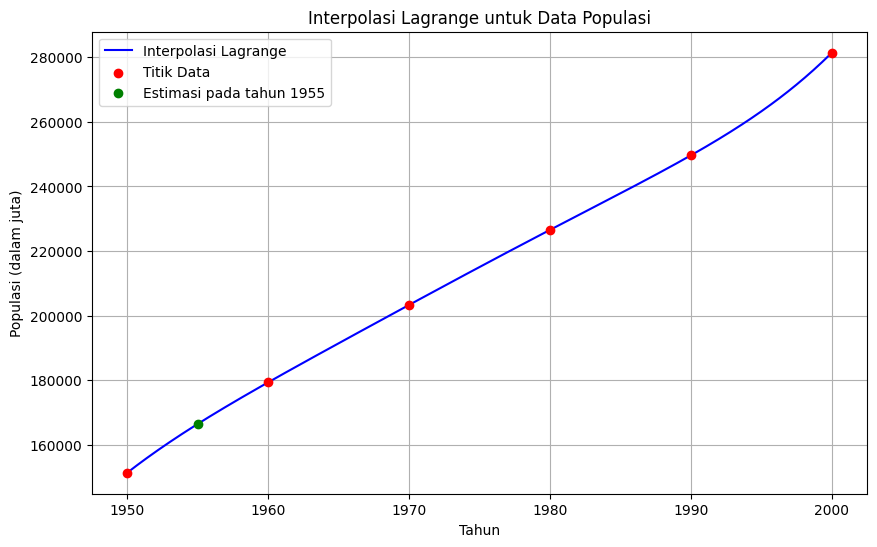

In [2]:
# Definisikan fungsi interpolasi Lagrange dengan output rinci
def interpolasi_lagrange(x, data_x, data_y):
    n = len(data_x)
    P = 0  # Inisialisasi nilai polinomial
    kontribusi = []  # Simpan setiap suku untuk tabel

    for i in range(n):
        # Hitung polinomial basis Lagrange ke-i, L_i(x)
        L_i = 1
        for j in range(n):
            if j != i:
                L_i *= (x - data_x[j]) / (data_x[i] - data_x[j])
        # Kontribusi dari suku ini
        suku = data_y[i] * L_i
        P += suku
        # Simpan detail: i, x_i, y_i, L_i(x), y_i * L_i(x)
        kontribusi.append((i, data_x[i], data_y[i], L_i, suku))

    return P, kontribusi

# Minta input tahun dari pengguna
x_cari = int(input("Masukkan tahun yang ingin dicari: "))

# Hitung interpolasi dan dapatkan kontribusi
estimasi_populasi, kontribusi = interpolasi_lagrange(x_cari, tahun, populasi)

# Tampilkan proses interpolasi dalam bentuk tabel
print("\nProses Interpolasi Lagrange:")
print(f"{'i':<5} {'x_i':<10} {'y_i':<15} {'L_i(x)':<20} {'y_i * L_i(x)':<20}")
print("-" * 70)
for i, x_i, y_i, L_i, suku in kontribusi:
    print(f"{i:<5} {x_i:<10} {y_i:<15} {L_i:<20.6f} {suku:<20.2f}")
print("-" * 70)
print(f"Hasil interpolasi P({x_cari}) = {estimasi_populasi:.2f}")

# Evaluasi polinomial pada rentang nilai untuk plot
x_nilai = np.linspace(1950, 2000, 500)  # 500 titik antara 1950 dan 2000
y_nilai = np.array([interpolasi_lagrange(x, tahun, populasi)[0] for x in x_nilai])

# Plot hasil
plt.figure(figsize=(10, 6))
plt.plot(x_nilai, y_nilai, label='Interpolasi Lagrange', color='blue')
plt.scatter(tahun, populasi, color='red', label='Titik Data', zorder=5)
plt.scatter([x_cari], [estimasi_populasi], color='green', label=f'Estimasi pada tahun {x_cari}', zorder=5)
plt.xlabel('Tahun')
plt.ylabel('Populasi (dalam juta)')
plt.title('Interpolasi Lagrange untuk Data Populasi')
plt.legend()
plt.grid(True)
plt.show()

# Newton Forward Interpolation

## Pendahuluan
Metode interpolasi Newton Forward digunakan untuk memperkirakan nilai fungsi pada titik yang tidak terdaftar dalam data yang ada. Metode ini sangat berguna ketika kita memiliki data yang teratur dan ingin memperkirakan nilai di titik yang lebih kecil dari titik pertama dalam data. Dalam interpolasi forward, kita menggunakan titik-titik data yang lebih awal untuk memperkirakan nilai di titik yang lebih baru.

Misalkan kita memiliki $n + 1$ titik data $(x_0, f(x_0)), (x_1, f(x_1)), \ldots, (x_n, f(x_n))$. Polinomial interpolasi Newton Forward dapat dinyatakan sebagai:

$$
P(x) = f(x_0) + \frac{(x - x_0)}{h1!} \Delta f(x_0) + \frac{(x - x_0)(x - x_1)}{h^2 2!} \Delta^2 f(x_0) + \cdots + \frac{(x - x_0)(x - x_1) \cdots (x - x_{k-1})}{h^kk!} \Delta^k f(x_0)
$$

Di mana $h$ adalah interval tetap antara titik-titik data, dan $\Delta f(x_0)$ adalah selisih pertama dari fungsi pada titik $x_0$.

## Persamaan Polinomial

Polinomial interpolasi Newton Forward yang digunakan dalam studi kasus ini dapat dinyatakan sebagai:

$$
P(x) = f(x_0) + \frac{(x - x_0)}{h} \Delta f(x_0) + \frac{(x - x_0)(x - x_1)}{2! h^2} \Delta^2 f(x_0) + \cdots
$$

Dengan cara ini, kita dapat memperkirakan nilai populasi untuk tahun-tahun yang tidak terdaftar dalam data asli, seperti tahun 1975, dengan menggunakan polinomial yang dihasilkan dari metode interpolasi Newton Forward. Metode ini memberikan pendekatan yang akurat untuk memperkirakan nilai berdasarkan data yang ada, dan sangat berguna dalam analisis data populasi dan tren demografis.

Masukkan tahun yang ingin dicari: 1955

Proses Interpolasi Newton Forward Difference:
k     Delta^k y_0     Binomial(s,k)        Suku                
------------------------------------------------------------
0     151326.00       1.000000             151326.00           
1     27997.00        0.500000             13998.50            
2     -4018.00        -0.125000            502.25              
3     3279.00         0.062500             204.94              
4     -2689.00        -0.039062            105.04              
5     10946.00        0.027344             299.30              
------------------------------------------------------------
Hasil interpolasi P(1955) = 166436.03


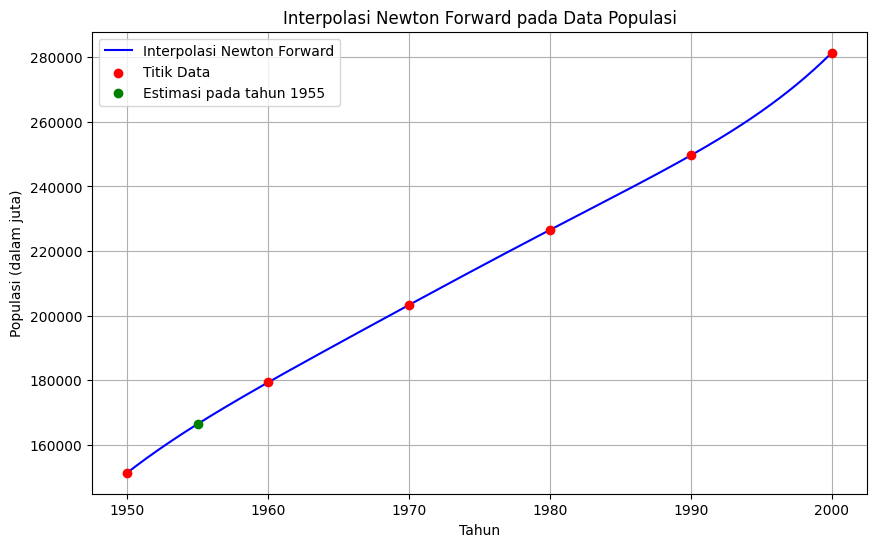

In [3]:
# Hitung selisih maju
def hitung_selisih_maju(data_y):
    n = len(data_y)
    selisih = [data_y.copy()]  # Selisih ke-0 adalah data asli

    for k in range(1, n):
        selisih_sebelumnya = selisih[-1]
        selisih_berikutnya = np.array([selisih_sebelumnya[i+1] - selisih_sebelumnya[i] for i in range(len(selisih_sebelumnya)-1)])
        selisih.append(selisih_berikutnya)

    return selisih

# Definisikan fungsi Interpolasi Newton Forward
def interpolasi_newton_maju(x, data_x, data_y):
    h = data_x[1] - data_x[0]  # Panjang langkah (10 tahun)
    s = (x - data_x[0]) / h    # Jarak yang dinormalisasi dari x_0
    selisih = hitung_selisih_maju(data_y)
    n = len(data_x)
    P = 0  # Inisialisasi nilai polinomial
    kontribusi = []  # Simpan setiap suku

    # Hitung setiap suku polinomial
    for k in range(n):
        # Hitung koefisien binomial: s(s-1)...(s-k+1) / k!
        binomial_s = 1
        for j in range(k):
            binomial_s *= (s - j)
        binomial_s /= factorial(k)
        # Selisih ke-k di titik awal (selisih[k][0])
        delta_k = selisih[k][0]
        # Kontribusi suku ini
        suku = delta_k * binomial_s
        P += suku
        # Simpan detail: k, Delta^k y_0, koefisien binomial, suku
        kontribusi.append((k, delta_k, binomial_s, suku))

    return P, kontribusi

# Ambil input pengguna untuk tahun yang dicari
x_uji = int(input("Masukkan tahun yang ingin dicari: "))

# Hitung interpolasi dan dapatkan kontribusi
estimasi_populasi, kontribusi = interpolasi_newton_maju(x_uji, tahun, populasi)

# Tampilkan proses interpolasi dalam bentuk tabel
print("\nProses Interpolasi Newton Forward Difference:")
print(f"{'k':<5} {'Delta^k y_0':<15} {'Binomial(s,k)':<20} {'Suku':<20}")
print("-" * 60)
for k, delta_k, binom_s, suku in kontribusi:
    print(f"{k:<5} {delta_k:<15.2f} {binom_s:<20.6f} {suku:<20.2f}")
print("-" * 60)
print(f"Hasil interpolasi P({x_uji}) = {estimasi_populasi:.2f}")

# Evaluasi polinomial dalam rentang nilai untuk plotting
x_nilai = np.linspace(1950, 2000, 500)
y_nilai = np.array([interpolasi_newton_maju(x, tahun, populasi)[0] for x in x_nilai])

# Plot hasilnya
plt.figure(figsize=(10, 6))
plt.plot(x_nilai, y_nilai, label='Interpolasi Newton Forward', color='blue')
plt.scatter(tahun, populasi, color='red', label='Titik Data', zorder=5)
plt.scatter([x_uji], [estimasi_populasi], color='green', label=f'Estimasi pada tahun {x_uji}', zorder=5)
plt.xlabel('Tahun')
plt.ylabel('Populasi (dalam juta)')
plt.title('Interpolasi Newton Forward pada Data Populasi')
plt.legend()
plt.grid(True)
plt.show()

# Polinom Interpolasi Newton Backward

## Pendahuluan
Metode interpolasi Newton Backward digunakan untuk memperkirakan nilai fungsi pada titik yang tidak terdaftar dalam data yang ada. Metode ini sangat berguna ketika kita memiliki data yang teratur dan ingin memperkirakan nilai di titik yang lebih besar dari titik terakhir dalam data. Dalam interpolasi backward, kita menggunakan titik-titik data yang lebih akhir untuk memperkirakan nilai di titik yang lebih baru.

Misalkan kita memiliki $n + 1$ titik data $(x_0, f(x_0)), (x_1, f(x_1)), \ldots, (x_n, f(x_n))$. Polinomial interpolasi Newton Backward dapat dinyatakan sebagai:

$$
P(x) = f(x_n) + (x - x_n) ∇ f(x_n) + \frac{(x - x_n)(x - x_{n-1})}{2!} ∇^2 f(x_n) + \cdots + \frac{(x - x_n)(x - x_{n-1}) \cdots (x - x_{n-k+1})}{k!} ∇^k f(x_n)
$$

Di mana $h$ adalah interval tetap antara titik-titik data, dan $∇ f(x_n)$ adalah selisih pertama dari fungsi pada titik $x_n$.

## Persamaan Polinomial

Polinomial interpolasi Newton Backward yang digunakan dalam studi kasus ini dapat dinyatakan sebagai:

$$
P(x) = f(x_n) + \frac{(x - x_n)}{h} \Delta f(x_n) + \frac{(x - x_n)(x - x_{n-1})}{2! h^2} \Delta^2 f(x_n) + \cdots
$$

Dengan cara ini, kita dapat memperkirakan nilai populasi untuk tahun-tahun yang tidak terdaftar dalam data asli, seperti tahun 1975, dengan menggunakan polinomial yang dihasilkan dari metode interpolasi Newton Backward. Metode ini memberikan pendekatan yang akurat untuk memperkirakan nilai berdasarkan data yang ada, dan sangat berguna dalam analisis data populasi dan tren demografis.

Masukkan tahun yang ingin dicari: 1955

Proses Interpolasi Newton Backward Difference:
k     Nabla^k y_n     Binomial(s,k)        Suku                
------------------------------------------------------------
0     281422.00       1.000000             281422.00           
1     31789.00        -4.500000            -143050.50          
2     8698.00         7.875000             68496.75            
3     8847.00         -6.562500            -58058.44           
4     8257.00         2.460938             20319.96            
5     10946.00        -0.246094            -2693.74            
------------------------------------------------------------
Hasil interpolasi P(1955) = 166436.03


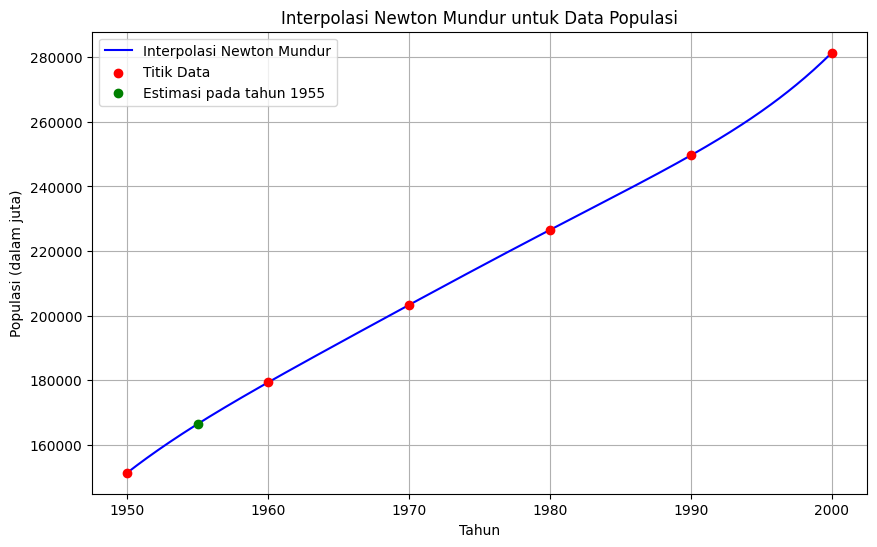

In [4]:
# Hitung selisih mundur
def hitung_selisih_mundur(data_y):

    n = len(data_y)
    diffs = [data_y.copy()]  # Selisih ke-0 adalah data asli

    for k in range(1, n):
        selisih_sebelumnya = diffs[-1]
        selisih_berikutnya = np.array([selisih_sebelumnya[i] - selisih_sebelumnya[i-1] for i in range(1, len(selisih_sebelumnya))])
        diffs.append(selisih_berikutnya)

    return diffs

# Definisikan fungsi interpolasi Newton mundur
def interpolasi_newton_mundur(x, data_x, data_y):

    h = data_x[1] - data_x[0]  # Jarak antar tahun (10 tahun)
    s = (x - data_x[-1]) / h   # Jarak ternormalisasi dari x_n (negatif jika x < x_n)
    diffs = hitung_selisih_mundur(data_y)
    n = len(data_x)
    P = 0  # Inisialisasi nilai polinom
    kontribusi = []  # Simpan setiap suku

    # Hitung setiap suku polinom
    for k in range(n):
        # Hitung koefisien binomial: s(s+1)...(s+k-1) / k!
        binomial_s = 1
        for j in range(k):
            binomial_s *= (s + j)
        binomial_s /= factorial(k)
        # Selisih ke-k pada titik terakhir (diffs[k][-1])
        delta_k = diffs[k][-1]
        # Kontribusi dari suku ini
        suku = delta_k * binomial_s
        P += suku
        # Simpan detail: k, Nabla^k y_n, koefisien binomial, suku
        kontribusi.append((k, delta_k, binomial_s, suku))

    return P, kontribusi

# Input tahun dari pengguna
x_uji = int(input("Masukkan tahun yang ingin dicari: "))

# Hitung interpolasi dan dapatkan kontribusi
estimasi_populasi, kontribusi = interpolasi_newton_mundur(x_uji, tahun, populasi)

# Tampilkan proses interpolasi dalam tabel
print("\nProses Interpolasi Newton Backward Difference:")
print(f"{'k':<5} {'Nabla^k y_n':<15} {'Binomial(s,k)':<20} {'Suku':<20}")
print("-" * 60)
for k, nabla_k, binom_s, suku in kontribusi:
    print(f"{k:<5} {nabla_k:<15.2f} {binom_s:<20.6f} {suku:<20.2f}")
print("-" * 60)
print(f"Hasil interpolasi P({x_uji}) = {estimasi_populasi:.2f}")

# Evaluasi polinom pada rentang nilai untuk plot
x_nilai = np.linspace(1950, 2000, 500)
y_nilai = np.array([interpolasi_newton_mundur(x, tahun, populasi)[0] for x in x_nilai])

# Plot hasil
plt.figure(figsize=(10, 6))
plt.plot(x_nilai, y_nilai, label='Interpolasi Newton Mundur', color='blue')
plt.scatter(tahun, populasi, color='red', label='Titik Data', zorder=5)
plt.scatter([x_uji], [estimasi_populasi], color='green', label=f'Estimasi pada tahun {x_uji}', zorder=5)
plt.xlabel('Tahun')
plt.ylabel('Populasi (dalam juta)')
plt.title('Interpolasi Newton Mundur untuk Data Populasi')
plt.legend()
plt.grid(True)
plt.show()

# Neville's Method

## Pendahuluan
Metode interpolasi Neville adalah teknik untuk memperkirakan nilai fungsi pada titik yang tidak terdaftar dalam data yang ada. Metode ini menggunakan pendekatan berbasis polinomial untuk menghitung nilai interpolasi dengan cara yang sistematis. Metode ini sangat berguna ketika kita memiliki data yang teratur dan ingin memperkirakan nilai di titik yang lebih kecil atau lebih besar dari titik yang ada.

Misalkan kita memiliki $n + 1$ titik data $(x_0, f(x_0)), (x_1, f(x_1)), \ldots, (x_n, f(x_n))$. Polinomial interpolasi Neville dapat dinyatakan dengan menggunakan tabel yang berisi nilai interpolasi bertahap. Nilai interpolasi pada titik $x$ dapat dihitung menggunakan rumus berikut:

$$
P(x) = P_{0,n}(x) = \frac{(x - x_0)P_{1,n}(x) - (x - x_n)P_{0,n-1}(x)}{x_n - x_0}
$$

Di mana $P_{i,j}(x)$ adalah polinomial interpolasi yang dihitung dari titik $x_i$ hingga $x_j$.

## Contoh Implementasi
Untuk menerapkan metode Neville, kita akan menggunakan data yang sama dengan yang digunakan dalam metode Lagrange untuk memperkirakan populasi pada tahun 1975.

$$
\begin{array}{c}
    \hline
    \textbf{Tahun} & \textbf{Populasi (dalam ribuan)} \\
    \hline
    1950 & 151,326 \\
    1960 & 179,323 \\
    1970 & 203,302 \\
    1980 & 226,542 \\
    1990 & 249,633 \\
    2000 & 281,422 \\
    \hline
\end{array}
$$

### Langkah-langkah Perhitungan

1. **Buat Tabel Neville**:
   Buat tabel yang berisi nilai fungsi dan nilai interpolasi bertahap. Setiap entri dalam tabel dihitung menggunakan rumus Neville.

2. **Hitung Nilai Interpolasi**:
   Gunakan rumus Neville untuk menghitung nilai interpolasi pada tahun 1975.

### Contoh Perhitungan

Misalkan kita menghitung nilai interpolasi untuk tahun 1975 menggunakan data di atas. Kita akan menghitung nilai interpolasi bertahap.

1. **Inisialisasi Tabel**:
   $$
   P_{i,i} = f(x_i)
   $$
   Untuk setiap $i$ dari 0 hingga $n$.

2. **Hitung Nilai Interpolasi Bertahap**:
   $$
   P_{i,j}(x) = \frac{(x - x_i)P_{i+1,j}(x) - (x - x_j)P_{i,j-1}(x)}{x_j - x_i}
   $$

3. **Contoh Tabel**:
   - Untuk $x_0 = 1950$ dan $x_1 = 1960$:
   $$
   P_{0,1}(1975) = \frac{(1975 - 1950)P_{1,1}(1975) - (1975 - 1960)P_{0,0}(1975)}{1960 - 1950}
   $$
   - Lanjutkan untuk semua kombinasi $i$ dan $j$.

### Menghitung Estimasi

Setelah menghitung nilai interpolasi, kita dapat menggunakan rumus Neville untuk menghitung estimasi populasi pada tahun 1975. Misalkan kita sudah menghitung semua nilai dalam tabel, kita akan mendapatkan:

$$
P(1975) = P_{0,n}(1975)
$$

### Kesimpulan

Dengan menggunakan metode interpolasi Neville, kita dapat memperkirakan nilai populasi untuk tahun-tahun yang tidak terdaftar dalam data asli, seperti tahun 1975. Metode ini memberikan pendekatan yang akurat untuk memperkirakan nilai berdasarkan data yang ada, dan sangat berguna dalam analisis data populasi dan tren demografis.

## Persamaan Polinomial

Polinomial interpolasi Neville yang digunakan dalam studi kasus ini dapat dinyatakan sebagai:

$$
P(x) = P_{0,n}(x) = \frac{(x - x_0)P_{1,n}(x) - (x - x_n)P_{0,n-1}(x)}{x_n - x_0}
$$

Dengan cara ini, kita dapat memperkirakan nilai populasi untuk tahun-tahun yang tidak terdaftar dalam data asli, seperti tahun 1975, dengan menggunakan polinomial yang dihasilkan dari metode interpolasi Neville. Metode ini memberikan pendekatan yang sistematis dan akurat untuk memperkirakan nilai berdasarkan data yang ada, dan sangat berguna dalam analisis data populasi dan tren demografis.

Masukkan tahun yang ingin dicari: 1955

Proses Interpolasi Neville:
k     Nilai                Deskripsi            Kontribusi          
-----------------------------------------------------------------
0     151326.00            Inisialisasi y_0     151326.00           
1     165324.50            P_0,1                165324.50           
1     167333.50            P_1,2                167333.50           
1     168442.00            P_2,3                168442.00           
1     168814.50            P_3,4                168814.50           
1     138371.50            P_4,5                138371.50           
2     165826.75            P_0,2                165826.75           
2     167056.38            P_1,3                167056.38           
2     168162.62            P_2,4                168162.62           
2     206868.25            P_3,5                206868.25           
3     166031.69            P_0,3                166031.69           
3     166872.00            P_1,4      

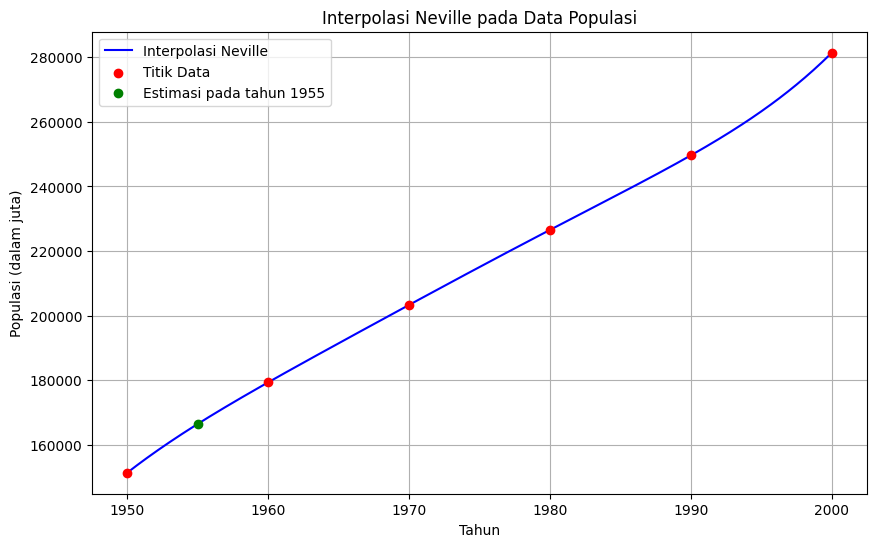

In [5]:
# Definisikan fungsi interpolasi Neville
def interpolasi_neville(x, x_data, y_data):

    n = len(x_data)
    # Inisialisasi tabel Neville dengan nilai y (P_{i,i})
    P = np.zeros((n, n))
    P[:, 0] = y_data.copy()

    # Kontribusi untuk tampilan: simpan setiap langkah perhitungan
    kontribusi = [(0, y_data[0], "Inisialisasi y_0", y_data[0])]

    # Isi tabel Neville
    for j in range(1, n):
        for i in range(n - j):
            pembilang = (x - x_data[i+j]) * P[i, j-1] - (x - x_data[i]) * P[i+1, j-1]
            penyebut = x_data[i] - x_data[i+j]
            P[i, j] = pembilang / penyebut
            # Simpan detail langkah: k, indeks i hingga i+j, P_{i,j}
            if j == n-1 and i == 0:  # Hasil akhir
                deskripsi_kontribusi = f"P_0,{j} (akhir)"
            else:
                deskripsi_kontribusi = f"P_{i},{i+j}"
            kontribusi.append((j, P[i, j], deskripsi_kontribusi, P[i, j]))

    return P[0, n-1], kontribusi

# Dapatkan input pengguna untuk tahun
tahun_uji = int(input("Masukkan tahun yang ingin dicari: "))

# Hitung interpolasi dan dapatkan kontribusi
estimasi_populasi, kontribusi = interpolasi_neville(tahun_uji, tahun, populasi)

# Tampilkan proses interpolasi dalam bentuk tabel
print("\nProses Interpolasi Neville:")
print(f"{'k':<5} {'Nilai':<20} {'Deskripsi':<20} {'Kontribusi':<20}")
print("-" * 65)
for k, nilai, deskripsi, kontrib in kontribusi:
    print(f"{k:<5} {nilai:<20.2f} {deskripsi:<20} {kontrib:<20.2f}")
print("-" * 65)
print(f"Hasil interpolasi P({tahun_uji}) = {estimasi_populasi:.2f}")

# Evaluasi polinomial pada rentang titik untuk plotting
x_nilai = np.linspace(1950, 2000, 500)
y_nilai = np.array([interpolasi_neville(x, tahun, populasi)[0] for x in x_nilai])

# Plot hasil
plt.figure(figsize=(10, 6))
plt.plot(x_nilai, y_nilai, label='Interpolasi Neville', color='blue')
plt.scatter(tahun, populasi, color='red', label='Titik Data', zorder=5)
plt.scatter([tahun_uji], [estimasi_populasi], color='green', label=f'Estimasi pada tahun {tahun_uji}', zorder=5)
plt.xlabel('Tahun')
plt.ylabel('Populasi (dalam juta)')
plt.title('Interpolasi Neville pada Data Populasi')
plt.legend()
plt.grid(True)
plt.show()

Tahun yang dicari: 1955

Proses Interpolasi Stirling Central Difference:
k     Delta^k         Description               Term                
-----------------------------------------------------------------
0     226542.00       y_2 (central)             226542.00           
1     23165.50        delta^1 avg (m±0)         -57913.75           
2     -149.00         delta^2 y_m               -465.62             
3     0.00            delta^3 avg (m±1)         -0.00               
4     8257.00         delta^4 y_m               11288.87            
5     0.00            delta^5 avg (m±2)         -0.00               
Hasil interpolasi P(1955) = 179451.49


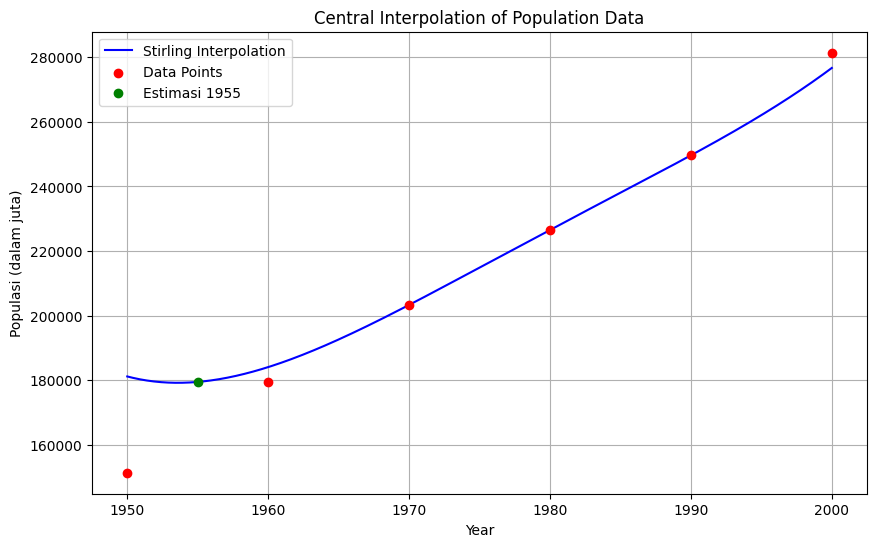

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

years = np.array([1950, 1960, 1970, 1980, 1990, 2000])
population = np.array([151326, 179323, 203302, 226542, 249633, 281422])

def compute_central_differences(y_data):
    diffs = [y_data.copy()]
    for k in range(1, len(y_data)):
        prev_diff = diffs[-1]
        next_diff = np.array([prev_diff[i+1] - prev_diff[i] for i in range(len(prev_diff)-1)])
        diffs.append(next_diff)
    return diffs

def stirling_interpolation(x, x_data, y_data):
    h = x_data[1] - x_data[0]
    m = len(x_data) // 2
    s = (x - x_data[m]) / h
    diffs = compute_central_differences(y_data)
    P = y_data[m]
    contributions = [(0, y_data[m], "y_2 (central)", y_data[m])]

    for k in range(1, len(x_data)):
        if k % 2 == 1:
            left_idx = m - (k//2) - 1
            right_idx = m - (k//2)
            delta_avg = 0
            if left_idx >= 0 and right_idx + 1 < len(diffs[k]):
                delta_avg = (diffs[k][left_idx] + diffs[k][right_idx]) / 2
            coeff = s
            for j in range(1, k, 2):
                coeff *= (s**2 - (j//2)**2)
            coeff /= factorial(k)
            term = delta_avg * coeff
            desc = f"delta^{k} avg (m±{k//2})"
        else:
            idx = m - (k//2)
            delta = diffs[k][idx] if 0 <= idx < len(diffs[k]) else 0
            coeff = s**2
            for j in range(2, k, 2):
                coeff *= (s**2 - (j//2)**2)
            coeff /= factorial(k)
            term = delta * coeff
            desc = f"delta^{k} y_m"

        P += term
        contributions.append((k, delta if k % 2 == 0 else delta_avg, desc, term))

    return P, contributions

# Test
x_test = int(input("Tahun yang dicari: "))
pop_estimate, contributions = stirling_interpolation(x_test, years, population)

print("\nProses Interpolasi Stirling Central Difference:")
print(f"{'k':<5} {'Delta^k':<15} {'Description':<25} {'Term':<20}")
print("-" * 65)
for k, delta_k, desc, term in contributions:
    print(f"{k:<5} {delta_k:<15.2f} {desc:<25} {term:<20.2f}")
print(f"Hasil interpolasi P({x_test}) = {pop_estimate:.2f}")

x_values = np.linspace(1950, 2000, 500)
y_values = np.array([stirling_interpolation(x, years, population)[0] for x in x_values])

plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values, label='Stirling Interpolation', color='blue')
plt.scatter(years, population, color='red', label='Data Points', zorder=5)
plt.scatter([x_test], [pop_estimate], color='green', label=f'Estimasi {x_test}', zorder=5)
plt.xlabel('Year')
plt.ylabel('Populasi (dalam juta)')
plt.title('Central Interpolation of Population Data')
plt.legend()
plt.grid(True)
plt.show()